# Классификация и локализация фигур
Лабораторная работа 10. Используем сгенерированные квадраты и круги на кадрах 32 × 32. Одна модель возвращает метку, рамку и маску. Для первого запуска нужны Python, PyTorch, Pillow и IPython. Загрузки данных нет. В коротком режиме используются 256/64/64 кадров и три эпохи; результаты полного режима приведены в главе.

In [1]:
from pathlib import Path
import sys
import torch

roots = (Path.cwd(), *Path.cwd().parents)
book = next((p for root in roots for p in (root, root / "Deep_Learning_Textbook")
             if (p / "Python_Code").is_dir()), None)
assert book is not None, "Откройте notebook из папки учебника"

sys.path.insert(0, str(book / "Python_Code" / "Chapter_10"))
from classification_localization import box_iou, mask_iou, mask_to_box, main

## Рамка и пересечение
Для координат xyxy используем полуоткрытые границы, включая левую и верхнюю и исключая правую и нижнюю.

In [2]:
a = torch.tensor([[1., 1., 5., 4.]])
b = torch.tensor([[2., 2., 6., 5.]])
expected_iou = 6 / 18
torch.testing.assert_close(box_iou(a, b), torch.tensor([expected_iou]))
mask = torch.zeros(5, 6, dtype=torch.bool)
for x, y in [(2,1),(3,1),(1,2),(2,2),(3,2),(4,2),(2,3),(3,3)]:
    mask[y, x] = True
assert mask_to_box(mask).tolist() == [1, 1, 5, 4]
assert mask.sum().item() == 8
print(f"Проверено: IoU рамок {expected_iou:.6f}; маска {mask.sum().item()} пикселей.")

Проверено: IoU рамок 0.333333; маска 8 пикселей.


## Опыт на CPU
Контрольная точка выбирается по общей потере на validation. Для теста отдельно измеряются доля верных классов, средний IoU рамок, совместное попадание и средний IoU масок.

In [3]:
result = main(["--profile", "short", "--seed", "42", "--device", "cpu"])
for key in ("accuracy", "box_miou", "joint_at_05", "mask_miou"):
    assert 0 <= result[key] <= 1
assert result["joint_at_05"] <= result["accuracy"]

profile=short torch=2.10.0+cpu device=cpu seed=42 train=256 val=64 test=64 parameters=105407
epoch=1 train_loss=1.8223
validation loss=1.5148 accuracy=0.5156 box_miou=0.2288 joint_at_05=0.0156 mask_miou=0.0000
epoch=2 train_loss=1.4743
validation loss=1.2156 accuracy=0.5000 box_miou=0.4480 joint_at_05=0.2500 mask_miou=0.0000
epoch=3 train_loss=1.1385
validation loss=1.0624 accuracy=0.5469 box_miou=0.5842 joint_at_05=0.4062 mask_miou=0.0000
best_epoch=3
test loss=1.0813 accuracy=0.4531 box_miou=0.5703 joint_at_05=0.2656 mask_miou=0.0000
example [20.0, 9.0, 30.0, 19.0] [17.693401336669922, 8.941333770751953, 29.59540557861328, 19.274221420288086]


## Интерпретация одного кадра
Оранжевая рамка соответствует эталону, бирюзовая — прогнозу. На второй и третьей панелях показаны бинарные маски. Один визуальный пример проверяет соглашения о координатах, а общая таблица описывает всю выборку.

Истинная / предсказанная метка: 0 1


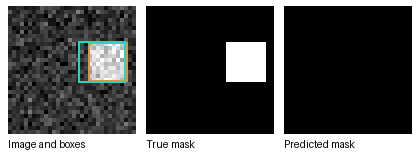

In [4]:
from io import BytesIO
from PIL import Image, ImageDraw
from IPython.display import Image as DisplayImage, display

example = result["example"]
panels = Image.new("RGB", (420, 156), "white")
for i, key in enumerate(("image", "true_mask", "predicted_mask")):
    img = Image.frombytes("L", (32,32), bytes((example[key].float()*255).flatten().to(torch.uint8).tolist()))
    panels.paste(img.resize((128,128), Image.Resampling.NEAREST).convert("RGB"), (8+i*138, 6))
draw = ImageDraw.Draw(panels)
for key, color in (("true_box","#e09542"), ("predicted_box","#29d3bc")):
    x0, y0, x1, y1 = example[key].tolist()
    draw.rectangle((8+4*x0, 6+4*y0, 8+4*x1-1, 6+4*y1-1), outline=color, width=2)
for i, label in enumerate(("Image and boxes", "True mask", "Predicted mask")):
    draw.text((8+i*138, 138), label, fill="black")
buffer = BytesIO()
panels.save(buffer, format="PNG")
display(DisplayImage(data=buffer.getvalue()))
print("Истинная / предсказанная метка:", example["true_label"], example["predicted_label"])

## Задания
A. Сверьте обе рамки и вычислите IoU вручную. B. Сравните ошибку рамки и маски на нескольких кадрах. C. Спроектируйте эксперимент с отключением пропускной связи и сохраните единый split, пороги и seed. Результаты дополнительных экспериментов записывайте отдельно.